# Comprehensions in Python

A **comprehension** builds a new list, dict or set from an iterable in one expression. It combines a loop and an optional condition. Comprehensions are shorter than the equivalent loop and never slower.

**After this lesson you can:**

1. Write list, dict and set comprehensions.
2. Add filters and conditional expressions.
3. Use generator expressions to save memory.
4. Decide when a normal loop is clearer.

## 1. List Comprehensions

```python
[expression for item in iterable if condition]
```

The expression is evaluated for every item that passes the condition. The code below shows a loop and the equivalent comprehension.

In [1]:
prices = [12.5, 7.0, 25.0, 3.2, 18.9]

# loop version
with_tax = []
for p in prices:
    with_tax.append(round(p * 1.2, 2))

# comprehension version
with_tax_c = [round(p * 1.2, 2) for p in prices]
print(with_tax == with_tax_c, with_tax_c)

expensive = [p for p in prices if p > 10]                 # filter
labels = ["high" if p > 10 else "low" for p in prices]    # conditional expression
print("expensive:", expensive)
print("labels   :", labels)

True [15.0, 8.4, 30.0, 3.84, 22.68]
expensive: [12.5, 25.0, 18.9]
labels   : ['high', 'low', 'high', 'low', 'high']


Note the two positions of `if`:

- `[x for x in data if cond]`: a **filter**; items that fail are removed.
- `[a if cond else b for x in data]`: a **conditional expression**; every item produces a value.

## 2. Dict and Set Comprehensions

In [2]:
words = ["data", "model", "python", "data", "train", "model", "data"]

lengths = {w: len(w) for w in words}                      # dict: word -> length (duplicates collapse)
unique_first_letters = {w[0] for w in words}              # set
counts = {w: words.count(w) for w in set(words)}          # simple word count

print("lengths:", lengths)
print("first letters:", unique_first_letters)
print("counts:", dict(sorted(counts.items(), key=lambda kv: -kv[1])))

inverted = {v: k for k, v in {"TR": "Türkiye", "DE": "Germany"}.items()}   # swap keys and values
print("inverted:", inverted)

lengths: {'data': 4, 'model': 5, 'python': 6, 'train': 5}
first letters: {'p', 'm', 'd', 't'}
counts: {'data': 3, 'model': 2, 'python': 1, 'train': 1}
inverted: {'Türkiye': 'TR', 'Germany': 'DE'}


## 3. Nested Comprehensions

A comprehension can contain several `for` clauses. They run in the same order as nested loops: the first `for` is the outer loop.

In [3]:
matrix = [[1, 2, 3], [4, 5, 6]]
flat = [x for row in matrix for x in row]                 # flatten
transposed = [[row[i] for row in matrix] for i in range(3)]
pairs = [(c, s) for c in "AB" for s in (1, 2)]
print(flat)
print(transposed)
print(pairs)

[1, 2, 3, 4, 5, 6]
[[1, 4], [2, 5], [3, 6]]
[('A', 1), ('A', 2), ('B', 1), ('B', 2)]


## 4. Generator Expressions

Round brackets create a **generator expression**. It produces the values one at a time instead of building the full list in memory. Use it when you only need to iterate once, for example inside `sum()`, `max()` or `any()`.

In [4]:
import sys

n = 1_000_000
as_list = [x * x for x in range(n)]
as_gen = (x * x for x in range(n))
print(f"list object     : {sys.getsizeof(as_list) / 1e6:6.2f} MB (plus the int objects)")
print(f"generator object: {sys.getsizeof(as_gen):6d} bytes")
print("sum via generator:", sum(x * x for x in range(n)))
print("any value > 10**11?", any(x * x > 10**11 for x in range(n)))

list object     :   8.45 MB (plus the int objects)
generator object:    200 bytes
sum via generator: 333332833333500000
any value > 10**11? True


## 5. Speed: Loop vs Comprehension vs `map`

The experiment measures three ways to square the numbers 0 … $n-1$.

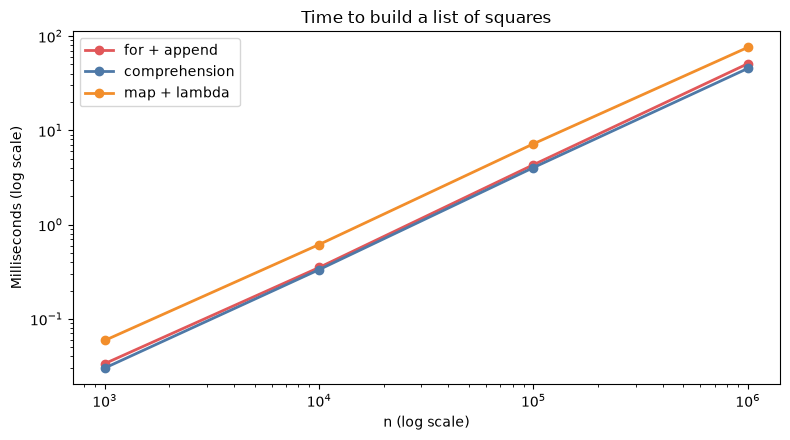

for + append   n=1,000,000:    50.9 ms
comprehension  n=1,000,000:    45.3 ms
map + lambda   n=1,000,000:    75.7 ms
loop / comprehension time ratio: 1.12


In [5]:
import timeit

import matplotlib.pyplot as plt

def with_loop(n):
    out = []
    for x in range(n):
        out.append(x * x)
    return out

def with_comprehension(n):
    return [x * x for x in range(n)]

def with_map(n):
    return list(map(lambda x: x * x, range(n)))

sizes = [1_000, 10_000, 100_000, 1_000_000]
methods = {"for + append": with_loop, "comprehension": with_comprehension, "map + lambda": with_map}
timings = {name: [] for name in methods}
for n in sizes:
    for name, fn in methods.items():
        timings[name].append(min(timeit.repeat(lambda: fn(n), number=3, repeat=3)) / 3 * 1000)

fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, ts), color in zip(timings.items(), ["#E15759", "#4E79A7", "#F28E2B"]):
    ax.plot(sizes, ts, marker="o", lw=2, color=color, label=name)
ax.set(xscale="log", yscale="log", title="Time to build a list of squares",
       xlabel="n (log scale)", ylabel="Milliseconds (log scale)")
ax.legend()
plt.tight_layout()
plt.show()

i = sizes.index(1_000_000)
for name in methods:
    print(f"{name:<14} n=1,000,000: {timings[name][i]:7.1f} ms")
print(f"loop / comprehension time ratio: {timings['for + append'][i] / timings['comprehension'][i]:.2f}")

In Python 3.12 the comprehension and the `for` loop run at almost the same speed: the interpreter optimises both. (In Python 3.10 and older, the comprehension was clearly faster, because the loop looked up `out.append` on every step.) `map` with a `lambda` is the slowest: every call to the lambda is a full Python function call. So the main reason to use a comprehension is readability, not speed.

*Insight: Use a comprehension when you build one new collection with a short expression. Use a normal loop when the body has several steps, side effects (printing, writing files) or error handling; readability is more important than one line.*

## Real-World Use Case or Analogy

A comprehension is like a **sorting machine in a fruit factory**: fruit goes in (the iterable), the machine removes bad fruit (the filter), washes each good fruit (the expression) and fills a new box (the new list). One machine does what three workers did in sequence.

Data engineers use comprehensions for small transformations everywhere: cleaning column names (`[c.strip().lower() for c in df.columns]`), building lookup tables (`{row.id: row for row in rows}`) and extracting fields from JSON records.